# Métricas extra sobre la ablación de bloques — effective rank y CKA (2026-08-30)

Extiende `notebooks/22082026_ablation/ablation.ipynb` y `notebooks/23082026_block_cutoff/block_cutoff.ipynb`
con métricas geométricas (bloque A del capítulo, *feature study* — punto **A.1** de `CLAUDE.md`)
para el ViT de 4 bloques entrenado en AwA2.

**Ambos modelos en una corrida.** La celda de configuración carga `MODELS = {"baseline": ..., "interpretable": ...}`; cada tarea de abajo calcula y grafica para los dos, guardando cada imagen con el nombre del modelo correspondiente en el archivo (sin pisarse entre sí).

Métricas (todas sobre el **mismo sample de referencia n=1000** que usó la ablación previa, para que
los números sean comparables entre corridas):

1. **Effective rank de fc1 (MLP) por bloque** — sobre los pesos de la primera lineal del MLP
   (`block.mlp.dense_1`, la que expande `hidden_size -> intermediate_size`).
2. **Effective rank del clasificador final** — sobre `model.classifier.weight` (mapea al espacio de clases de AwA2).
3. **Effective rank del attention output por bloque** — sobre activaciones: salida de la proyección
   final de atención (tras concatenar cabezas, **antes** del residual add — mismo punto de captura que
   `forward_with_head_ablated` en `ablation.ipynb`), aplanadas sobre `samples * seq_len`.
4. **Matriz CKA 4x4** (linear CKA, Kornblith et al. 2019) entre los attention outputs de los 4 bloques.

Effective rank = `exp(H(sigma_norm))` (Roy & Vetterli 2007), reutilizando `modules.effective_rank.effective_rank`.

Cada tarea **calcula y grafica en su propia celda**, con el eje llevado hasta el máximo teórico de esa
métrica (`min(dims)` para los effective ranks, `1.0` para el CKA), para que las gráficas de los dos modelos se puedan poner lado a lado directamente. Toda gráfica se guarda como PNG en `OUTPUT_DIR` con el nombre del modelo en el archivo, además de mostrarse inline; el nombre exacto con el que se guardó se imprime debajo de cada gráfica.

## 0. Configuración — carga ambos modelos

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Misma convención que el resto de notebooks/: vive 2 niveles bajo la raíz del proyecto.
project_root = Path.cwd().resolve().parents[1]
sys.path.append(str(project_root))

from modules.model import ViTForClassfication
from modules.datasets import AwA2Dataset
from modules.effective_rank import effective_rank
from modules.cka import linear_cka
from modules.figures import save_fig

torch.manual_seed(0)

N_REF = 1000  # sample de referencia (mismo que ablation.ipynb)

EXPERIMENTS_DIR = project_root / "experimentation" / "experiments"
OUTPUT_DIR = EXPERIMENTS_DIR / "30082026_block_extra_metrics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "unconstrained": "vit-15-AwA2",
    "constrained": "vit-15-constrained-AwA2",
    "constrained_rank": "vit-15-constrained_rank-AwA2",
}

print(f"OUTPUT_DIR : {OUTPUT_DIR.relative_to(project_root)}")
print(f"N_REF      : {N_REF}")

OUTPUT_DIR : experimentation/experiments/30082026_block_extra_metrics
N_REF      : 1000


## 1. Cargar los dos modelos

Mismo patrón que `ablation.ipynb` / `block_cutoff.ipynb`: `config.json` + `metrics.json` + `model_final.pt`,
con `map_location="cpu"` (los checkpoints se guardaron desde MPS). El `assert` sobre `use_faster_attention`
protege el resto del notebook, que asume cabezas separadas (`block.attention.heads`) y `block.mlp.dense_1`.

In [2]:
def load_model(name):
    exp_dir = EXPERIMENTS_DIR / name
    with open(exp_dir / "config.json") as f:
        config = json.load(f)
    with open(exp_dir / "metrics.json") as f:
        metrics = json.load(f)
    assert not config["use_faster_attention"], (
        "Este notebook asume atención no-fusionada (block.attention.heads / block.mlp.dense_1); "
        "con use_faster_attention=True habría que adaptar los puntos de captura."
    )
    model = ViTForClassfication(config)
    model.load_state_dict(torch.load(exp_dir / "model_final.pt", map_location="cpu"))
    model.eval()
    return model, config, metrics


models = {key: load_model(name) for key, name in MODELS.items()}

config = models["unconstrained"][1]
assert all(m[1] == config for m in models.values()), "Los modelos deben tener la misma arquitectura"

n_blocks          = len(models["unconstrained"][0].encoder.blocks)
n_heads           = config["num_attention_heads"]
hidden_size       = config["hidden_size"]
intermediate_size = config["intermediate_size"]
num_classes       = config["num_classes"]
block_labels      = [f"block {i + 1}" for i in range(n_blocks)]

for key, (_, _, metrics) in models.items():
    print(f"{key:>13} ({MODELS[key]}): accuracy de entrenamiento = {metrics['accuracy']:.4f}")
print(f"bloques={n_blocks} | cabezas/bloque={n_heads} | hidden={hidden_size} "
      f"| intermediate={intermediate_size} | clases={num_classes}")

unconstrained (vit-15-AwA2): accuracy de entrenamiento = 0.2971
  constrained (vit-15-constrained-AwA2): accuracy de entrenamiento = 0.2879
constrained_rank (vit-15-constrained_rank-AwA2): accuracy de entrenamiento = 0.2973
bloques=4 | cabezas/bloque=4 | hidden=48 | intermediate=192 | clases=50


## 2. Sample de referencia (n = 1000)

Exactamente el mismo lote para los dos modelos: primeras `N_REF` imágenes del test de AwA2
(`get_samples_from_indices(range(N_REF), set="test")`). `AwA2Dataset` usa el cache local ya construido
en `data/awa2/`, así que no vuelve a descargar nada.

In [3]:
dataset = AwA2Dataset(image_size=32, root=str(project_root / "data" / "awa2"))
_, testloader, classes = dataset.get_loaders(batch_size=256)

# Muestra aleatoria con semilla fija: el testset de AwA2 viene ordenado por clase, así que las primeras N
# imágenes cubrirían solo unas pocas clases.
ref_images, ref_labels = dataset.get_samples_from_indices(torch.randperm(len(dataset.testset), generator=torch.Generator().manual_seed(0))[:N_REF].tolist(), device="cpu", set="test")
print(f"Sample de referencia: {tuple(ref_images.shape)}  (índices 0..{N_REF - 1} del test)")

Sample de referencia: (1000, 3, 32, 32)  (índices 0..999 del test)


## Tarea 1 — Effective rank de los pesos de fc1 (MLP) por bloque

`fc1` / `linear1` = la primera lineal del MLP, la que **expande** la dimensión antes de la activación.
En `modules/model.py` es `block.mlp.dense_1`; su `weight` tiene shape `(intermediate_size, hidden_size)`
= `(192, 48)`. Effective rank vía SVD: valores singulares -> normalizar como distribución (dividir por
su suma) -> `exp(entropía)` (Roy & Vetterli 2007).

**Máximo teórico:** `min(192, 48) = 48` (la línea punteada y el tope del eje `y` de la gráfica).

[unconstrained] block 1: fc1 weight (192, 48)  ->  effective_rank = 37.7460
[unconstrained] block 2: fc1 weight (192, 48)  ->  effective_rank = 39.3459
[unconstrained] block 3: fc1 weight (192, 48)  ->  effective_rank = 39.6164
[unconstrained] block 4: fc1 weight (192, 48)  ->  effective_rank = 40.2747
guardado: experimentation/experiments/30082026_block_extra_metrics/effrank_mlp_fc1_by_block_vit-15-AwA2.png


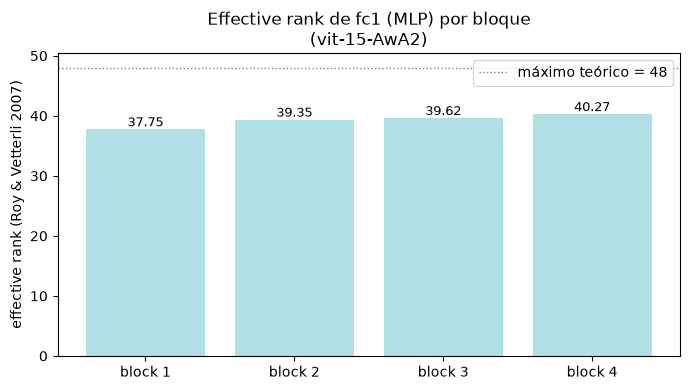

[constrained] block 1: fc1 weight (192, 48)  ->  effective_rank = 36.2229
[constrained] block 2: fc1 weight (192, 48)  ->  effective_rank = 38.9232
[constrained] block 3: fc1 weight (192, 48)  ->  effective_rank = 34.9255
[constrained] block 4: fc1 weight (192, 48)  ->  effective_rank = 39.5577
guardado: experimentation/experiments/30082026_block_extra_metrics/effrank_mlp_fc1_by_block_vit-15-constrained-AwA2.png


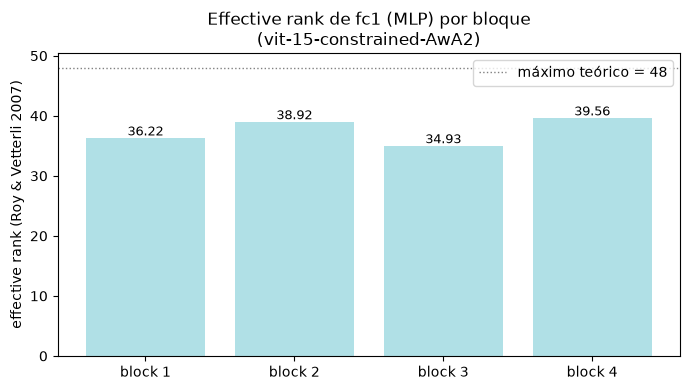

[constrained_rank] block 1: fc1 weight (192, 48)  ->  effective_rank = 38.6756
[constrained_rank] block 2: fc1 weight (192, 48)  ->  effective_rank = 37.0738
[constrained_rank] block 3: fc1 weight (192, 48)  ->  effective_rank = 35.6373
[constrained_rank] block 4: fc1 weight (192, 48)  ->  effective_rank = 39.1273


guardado: experimentation/experiments/30082026_block_extra_metrics/effrank_mlp_fc1_by_block_vit-15-constrained_rank-AwA2.png


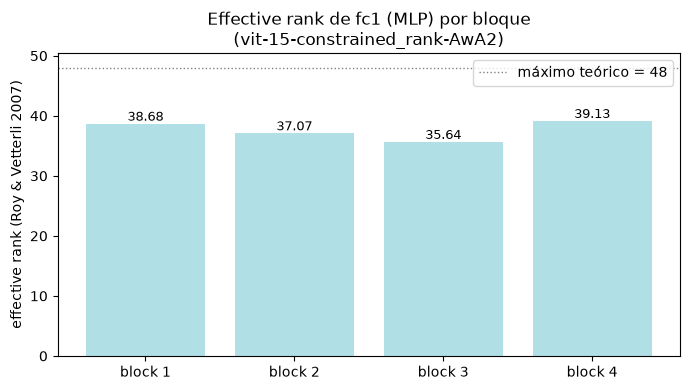

In [4]:
max_erank_mlp = min(intermediate_size, hidden_size)

erank_mlp = {}
for key, (model, _, _) in models.items():
    erank_mlp[key] = []
    for i, block in enumerate(model.encoder.blocks):
        W = block.mlp.dense_1.weight.detach()          # (intermediate_size, hidden_size)
        er = effective_rank(W).item()
        erank_mlp[key].append(er)
        print(f"[{key}] block {i + 1}: fc1 weight {tuple(W.shape)}  ->  effective_rank = {er:.4f}")

    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(block_labels, erank_mlp[key], color="powderblue")
    for rect, v in zip(bars, erank_mlp[key]):
        ax.text(rect.get_x() + rect.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.axhline(max_erank_mlp, color="gray", linestyle=":", linewidth=1,
               label=f"máximo teórico = {max_erank_mlp}")
    ax.set_ylabel("effective rank (Roy & Vetterli 2007)")
    ax.set_title(f"Effective rank de fc1 (MLP) por bloque\n({MODELS[key]})")
    ax.set_ylim(0, max_erank_mlp * 1.05)
    ax.legend()
    plt.tight_layout()
    save_fig(fig, "effrank_mlp_fc1_by_block", OUTPUT_DIR, tag=MODELS[key], project_root=project_root)
    plt.show()

## Tarea 2 — Effective rank del clasificador final

`model.classifier` es la lineal final `hidden_size -> num_classes`; su `weight` tiene shape `(10, 48)`.
Mismo método que la Tarea 1.

**Máximo teórico:** `min(10, 48) = 10`.

[unconstrained] classifier weight (50, 48)  ->  effective_rank = 34.2573  (máximo teórico = 48)
guardado: experimentation/experiments/30082026_block_extra_metrics/effrank_classifier_vit-15-AwA2.png


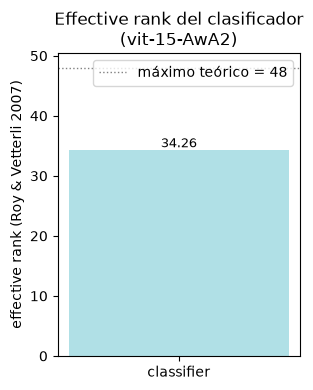

[constrained] classifier weight (50, 48)  ->  effective_rank = 33.2076  (máximo teórico = 48)
guardado: experimentation/experiments/30082026_block_extra_metrics/effrank_classifier_vit-15-constrained-AwA2.png


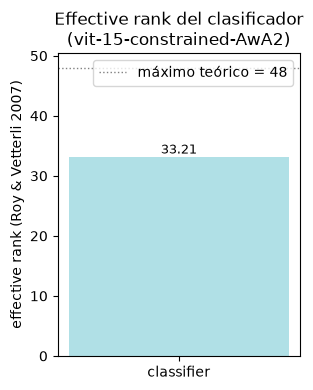

[constrained_rank] classifier weight (50, 48)  ->  effective_rank = 33.9293  (máximo teórico = 48)


guardado: experimentation/experiments/30082026_block_extra_metrics/effrank_classifier_vit-15-constrained_rank-AwA2.png


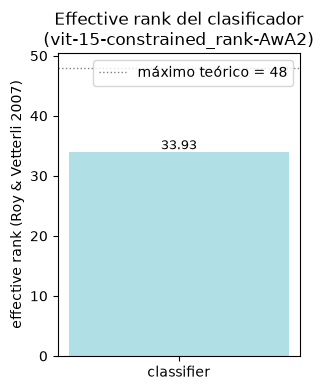

In [5]:
max_erank_classifier = min(num_classes, hidden_size)

erank_classifier = {}
for key, (model, _, _) in models.items():
    W_clf = model.classifier.weight.detach()           # (num_classes, hidden_size)
    erank_classifier[key] = effective_rank(W_clf).item()
    print(f"[{key}] classifier weight {tuple(W_clf.shape)}  ->  effective_rank = {erank_classifier[key]:.4f}  "
          f"(máximo teórico = {max_erank_classifier})")

    fig, ax = plt.subplots(figsize=(3.2, 4))
    ax.bar(["classifier"], [erank_classifier[key]], color="powderblue", width=0.5)
    ax.text(0, erank_classifier[key], f"{erank_classifier[key]:.2f}", ha="center", va="bottom", fontsize=9)
    ax.axhline(max_erank_classifier, color="gray", linestyle=":", linewidth=1,
               label=f"máximo teórico = {max_erank_classifier}")
    ax.set_ylabel("effective rank (Roy & Vetterli 2007)")
    ax.set_title(f"Effective rank del clasificador\n({MODELS[key]})")
    ax.set_ylim(0, max_erank_classifier * 1.05)
    ax.legend()
    plt.tight_layout()
    save_fig(fig, "effrank_classifier", OUTPUT_DIR, tag=MODELS[key], project_root=project_root)
    plt.show()

## Tarea 3 — Effective rank del attention output por bloque (activaciones)

Punto de captura: **la salida de la proyección final de atención**, es decir el primer elemento que
devuelve `MultiHeadAttention.forward` (`attention_output`), que ya es `output_projection(concat(cabezas))`
tras el `output_dropout` y **antes** del residual add. Es exactamente el mismo punto que usa
`forward_with_head_ablated` en `notebooks/22082026_ablation/ablation.ipynb`, así que los números son
comparables con ese notebook.

Se captura con un `forward_hook` sobre cada `block.attention` durante un único forward sobre el sample
de referencia. Cada activación tiene shape `(N_REF, seq_len, hidden_size)` con `seq_len = num_patches + 1 = 65`.
Para el SVD se aplana sobre `samples * seq_len` -> matriz `(N_REF * 65, 48)`.

**Máximo teórico:** `min(N_REF * seq_len, hidden_size) = 48`.

[unconstrained] block 1: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 14.0653
[unconstrained] block 2: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 17.4248
[unconstrained] block 3: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 17.5077
[unconstrained] block 4: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 19.7855
guardado: experimentation/experiments/30082026_block_extra_metrics/effrank_attn_output_by_block_vit-15-AwA2.png


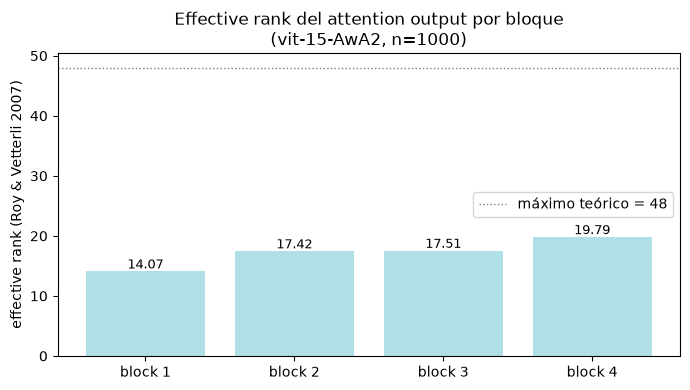

[constrained] block 1: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 10.9949
[constrained] block 2: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 15.7472
[constrained] block 3: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 19.2266
[constrained] block 4: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 18.1094
guardado: experimentation/experiments/30082026_block_extra_metrics/effrank_attn_output_by_block_vit-15-constrained-AwA2.png


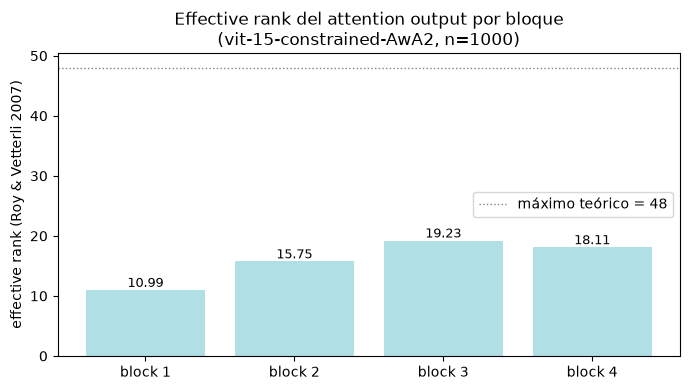

[constrained_rank] block 1: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 14.9143
[constrained_rank] block 2: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 15.8661
[constrained_rank] block 3: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 16.5457
[constrained_rank] block 4: activaciones (1000, 65, 48) -> aplanado (65000, 48) -> effective_rank = 19.9333
guardado: experimentation/experiments/30082026_block_extra_metrics/effrank_attn_output_by_block_vit-15-constrained_rank-AwA2.png


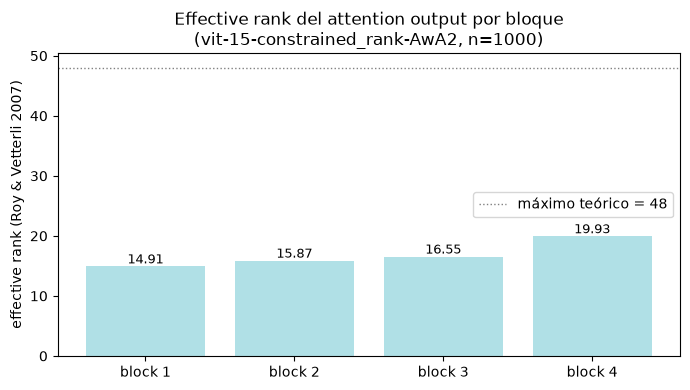

In [6]:
attn_out_flat = {}   # se reutiliza en la Tarea 4 (CKA)
erank_attn_out = {}

for key, (model, _, _) in models.items():
    attn_out_acts = {}

    def _make_hook(idx):
        def hook(module, inputs, output):
            # MultiHeadAttention.forward -> (attention_output, attention_probs);
            # attention_output = output_projection(concat(cabezas)) tras output_dropout,
            # ANTES del residual add. Mismo punto de captura que ablation.ipynb.
            attn_out_acts[idx] = output[0].detach()
        return hook

    handles = [
        block.attention.register_forward_hook(_make_hook(i))
        for i, block in enumerate(model.encoder.blocks)
    ]
    try:
        with torch.no_grad():
            _ = model(ref_images, output_attentions=False)
    finally:
        for h in handles:
            h.remove()

    erank_attn_out[key] = []
    attn_out_flat[key] = []
    for i in range(n_blocks):
        act  = attn_out_acts[i]                              # (N_REF, seq_len, hidden_size)
        flat = act.reshape(-1, act.shape[-1]).contiguous()   # (N_REF * seq_len, hidden_size)
        attn_out_flat[key].append(flat)
        er = effective_rank(flat).item()
        erank_attn_out[key].append(er)
        print(f"[{key}] block {i + 1}: activaciones {tuple(act.shape)} -> aplanado {tuple(flat.shape)} "
              f"-> effective_rank = {er:.4f}")

    max_erank_attn = min(attn_out_flat[key][0].shape[0], hidden_size)

    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(block_labels, erank_attn_out[key], color="powderblue")
    for rect, v in zip(bars, erank_attn_out[key]):
        ax.text(rect.get_x() + rect.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.axhline(max_erank_attn, color="gray", linestyle=":", linewidth=1,
               label=f"máximo teórico = {max_erank_attn}")
    ax.set_ylabel("effective rank (Roy & Vetterli 2007)")
    ax.set_title(f"Effective rank del attention output por bloque\n({MODELS[key]}, n={N_REF})")
    ax.set_ylim(0, max_erank_attn * 1.05)
    ax.legend()
    plt.tight_layout()
    save_fig(fig, "effrank_attn_output_by_block", OUTPUT_DIR, tag=MODELS[key], project_root=project_root)
    plt.show()

## Tarea 4 — Matriz de similitud CKA entre attention outputs de bloques

`linear_cka` (Kornblith et al. 2019, `modules/cka.py`) sobre las matrices aplanadas de la Tarea 3,
para los 6 pares `(1,2) (1,3) (1,4) (2,3) (2,4) (3,4)`. Matriz `4x4` simétrica con diagonal = 1.

**Máximo teórico:** `1.0` (idénticas salvo rotación/escala isotrópica). El heatmap usa escala de
color fija `vmin=0, vmax=1`, así que los mapas de las dos corridas se comparan directamente.

[unconstrained] CKA(block 1, block 2) = 0.4750
[unconstrained] CKA(block 1, block 3) = 0.3529
[unconstrained] CKA(block 1, block 4) = 0.1914
[unconstrained] CKA(block 2, block 3) = 0.4478
[unconstrained] CKA(block 2, block 4) = 0.2293
[unconstrained] CKA(block 3, block 4) = 0.2057
guardado: experimentation/experiments/30082026_block_extra_metrics/cka_attn_output_blocks_vit-15-AwA2.csv


guardado: experimentation/experiments/30082026_block_extra_metrics/cka_attn_output_blocks_heatmap_vit-15-AwA2.png


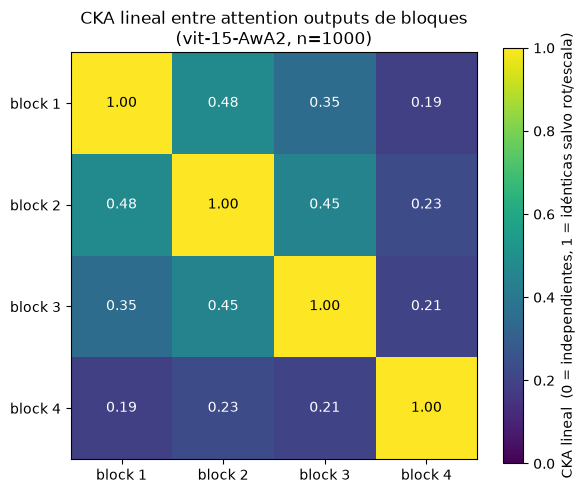

[constrained] CKA(block 1, block 2) = 0.4844
[constrained] CKA(block 1, block 3) = 0.3114
[constrained] CKA(block 1, block 4) = 0.1428
[constrained] CKA(block 2, block 3) = 0.3408
[constrained] CKA(block 2, block 4) = 0.0700
[constrained] CKA(block 3, block 4) = 0.1405
guardado: experimentation/experiments/30082026_block_extra_metrics/cka_attn_output_blocks_vit-15-constrained-AwA2.csv


guardado: experimentation/experiments/30082026_block_extra_metrics/cka_attn_output_blocks_heatmap_vit-15-constrained-AwA2.png


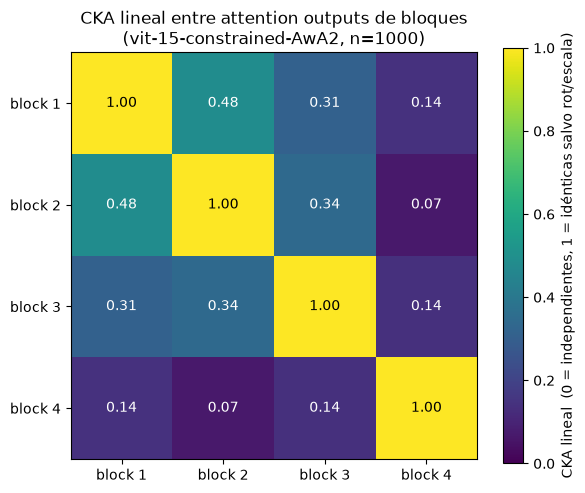

[constrained_rank] CKA(block 1, block 2) = 0.5616
[constrained_rank] CKA(block 1, block 3) = 0.2736
[constrained_rank] CKA(block 1, block 4) = 0.1078
[constrained_rank] CKA(block 2, block 3) = 0.4493
[constrained_rank] CKA(block 2, block 4) = 0.1647
[constrained_rank] CKA(block 3, block 4) = 0.1883
guardado: experimentation/experiments/30082026_block_extra_metrics/cka_attn_output_blocks_vit-15-constrained_rank-AwA2.csv


guardado: experimentation/experiments/30082026_block_extra_metrics/cka_attn_output_blocks_heatmap_vit-15-constrained_rank-AwA2.png


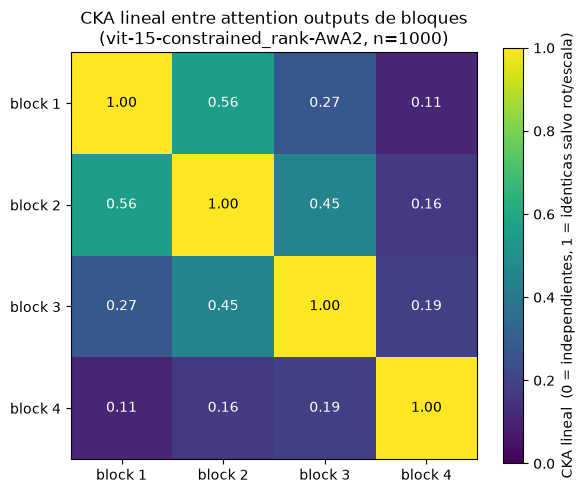

In [7]:
for key in MODELS:
    cka_matrix = np.eye(n_blocks)
    for a in range(n_blocks):
        for b in range(a + 1, n_blocks):
            val = linear_cka(attn_out_flat[key][a].float(), attn_out_flat[key][b].float()).item()
            cka_matrix[a, b] = val
            cka_matrix[b, a] = val
            print(f"[{key}] CKA(block {a + 1}, block {b + 1}) = {val:.4f}")

    cka_df = pd.DataFrame(cka_matrix,
                          index=[f"block_{i + 1}" for i in range(n_blocks)],
                          columns=[f"block_{i + 1}" for i in range(n_blocks)])
    cka_csv_path = OUTPUT_DIR / f"cka_attn_output_blocks_{MODELS[key]}.csv"
    cka_df.to_csv(cka_csv_path)
    print(f"guardado: {cka_csv_path.relative_to(project_root)}")

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cka_matrix, cmap="viridis", vmin=0.0, vmax=1.0)   # máximo teórico = 1.0
    ax.set_xticks(range(n_blocks)); ax.set_xticklabels(block_labels)
    ax.set_yticks(range(n_blocks)); ax.set_yticklabels(block_labels)
    for a in range(n_blocks):
        for b in range(n_blocks):
            ax.text(b, a, f"{cka_matrix[a, b]:.2f}", ha="center", va="center",
                    color="white" if cka_matrix[a, b] < 0.6 else "black", fontsize=10)
    ax.set_title(f"CKA lineal entre attention outputs de bloques\n({MODELS[key]}, n={N_REF})")
    fig.colorbar(im, ax=ax, label="CKA lineal  (0 = independientes, 1 = idénticas salvo rot/escala)")
    plt.tight_layout()
    save_fig(fig, "cka_attn_output_blocks_heatmap", OUTPUT_DIR, tag=MODELS[key], project_root=project_root)
    plt.show()

## Tabla resumen (CSV)

Los 9 effective ranks en una fila: `effective_rank_mlp_block_1..4`,
`effective_rank_attn_output_block_1..4`, `effective_rank_classifier`.

In [8]:
rows = []
for key in MODELS:
    row = {"model_name": MODELS[key], "variant": key}
    for i in range(n_blocks):
        row[f"effective_rank_mlp_block_{i + 1}"] = erank_mlp[key][i]
    for i in range(n_blocks):
        row[f"effective_rank_attn_output_block_{i + 1}"] = erank_attn_out[key][i]
    row["effective_rank_classifier"] = erank_classifier[key]
    rows.append(row)

df = pd.DataFrame(rows)
csv_path = OUTPUT_DIR / "effective_rank_metrics.csv"
df.to_csv(csv_path, index=False)
print(f"guardado: {csv_path.relative_to(project_root)}")
df

guardado: experimentation/experiments/30082026_block_extra_metrics/effective_rank_metrics.csv


,model_name,variant,effective_rank_mlp_block_1,effective_rank_mlp_block_2,effective_rank_mlp_block_3,effective_rank_mlp_block_4,effective_rank_attn_output_block_1,effective_rank_attn_output_block_2,effective_rank_attn_output_block_3,effective_rank_attn_output_block_4,effective_rank_classifier
0,vit-15-AwA2,unconstrained,37.746002,39.345943,39.616436,40.274651,14.065334,17.424812,17.507721,19.785522,34.257298
1,vit-15-constrained-AwA2,constrained,36.222870,38.923225,34.925522,39.557728,10.994946,15.747206,19.226568,18.109388,33.207626
2,vit-15-constrained_rank-AwA2,constrained_rank,38.675594,37.073833,35.637295,39.127285,14.914285,15.866061,16.545696,19.933268,33.929348


## Para reflexionar / siguientes pasos

Los dos modelos ya corren juntos en cada celda; el CSV final (sección 5) trae una fila por modelo para comparar directamente. La comparación (mismo eje/escala por construcción en cada gráfica):

- **Effective rank (fc1, clasificador, attention output):** la hipótesis del bloque A es que la
  penalización de información compartida **sube** el rango efectivo (menos redundancia -> se usan más
  direcciones del espacio) y/o lo hace **más uniforme entre bloques**.
- **CKA entre bloques:** la hipótesis es que el modelo interpretable tiene la matriz CKA **más fría
  fuera de la diagonal** (attention outputs de distintos bloques menos parecidos entre sí = menos
  información compartida entre bloques).
- Encaja con **A.1** de `CLAUDE.md`; el paso siguiente natural es replicar estas métricas núcleo sobre
  2-3 semillas (**C.6**, *universality*) para blindar el hallazgo.